<center><h1>bagai_sanchit_HW4</h1></center>
<br>
<br>

Name: Sanchit Bagai
<br>
Github Username: baked-potatoes
<br>
USC ID: 1033392623

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import os, re, glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, auc)
from sklearn.utils import resample
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

Get the AReM Data Set

In [2]:
data_dir = "../data/AReM"

files = sorted(glob.glob(os.path.join(data_dir, "**", "dataset*.csv"), recursive=True))
print("number of files:", len(files))

cols = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

def read_instance(path):
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = [p for p in re.split(r"[,\s]+", line) if p]
            try:
                vals = [float(p) for p in parts]
            except ValueError:
                continue
            if len(vals) == 7:
                rows.append(vals[1:])
    return pd.DataFrame(rows, columns=cols)

instances = []
for p in files:
    activity = os.path.basename(os.path.dirname(p))
    num = int(re.search(r"dataset(\d+)", os.path.basename(p)).group(1))
    df = read_instance(p)
    instances.append({"activity": activity, "num": num, "data": df})

print(pd.Series([len(i["data"]) for i in instances]).value_counts())

number of files: 88
480    87
479     1
Name: count, dtype: int64


### (b) Splitting Data

In [3]:
def is_test(inst):
    if inst["activity"] in ("bending1", "bending2"):
        return inst["num"] in (1, 2)
    return inst["num"] in (1, 2, 3)

train = [i for i in instances if not is_test(i)]
test  = [i for i in instances if is_test(i)]
print("train:", len(train), " test:", len(test))
print(pd.Series([i["activity"] for i in train]).value_counts().to_dict())

train: 69  test: 19
{'cycling': 12, 'lying': 12, 'sitting': 12, 'standing': 12, 'walking': 12, 'bending1': 5, 'bending2': 4}


### (c) Feature Extraction

In [4]:
def extract(inst):
    feats = {}
    for k, c in enumerate(cols, start=1):
        x = inst["data"][c].values
        feats[f"min{k}"]       = x.min()
        feats[f"max{k}"]       = x.max()
        feats[f"mean{k}"]      = x.mean()
        feats[f"median{k}"]    = np.median(x)
        feats[f"std{k}"]       = x.std(ddof=1)
        feats[f"1st_quart{k}"] = np.percentile(x, 25)
        feats[f"3rd_quart{k}"] = np.percentile(x, 75)
    return feats

features_all = pd.DataFrame([extract(i) for i in instances])
features_all.insert(0, "Instance", range(1, len(instances) + 1))

activity = pd.Series([i["activity"] for i in instances], name="activity")
test_mask = np.array([is_test(i) for i in instances])

features_train = features_all[~test_mask].reset_index(drop=True)
features_test  = features_all[test_mask].reset_index(drop=True)
y_train = activity[~test_mask].reset_index(drop=True)
y_test  = activity[test_mask].reset_index(drop=True)

print(features_all.shape, features_train.shape, features_test.shape)
features_all.head()

(88, 43) (69, 43) (19, 43)


,Instance,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,...,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
0,1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

bending: 9  other: 60


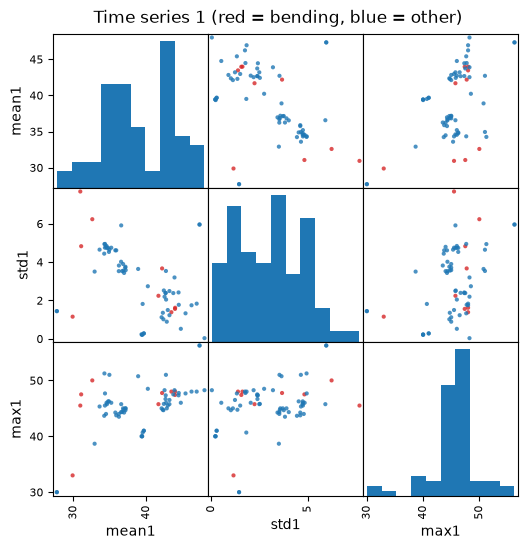

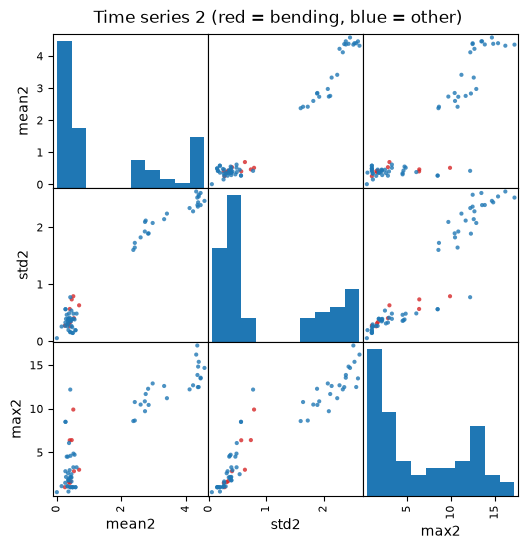

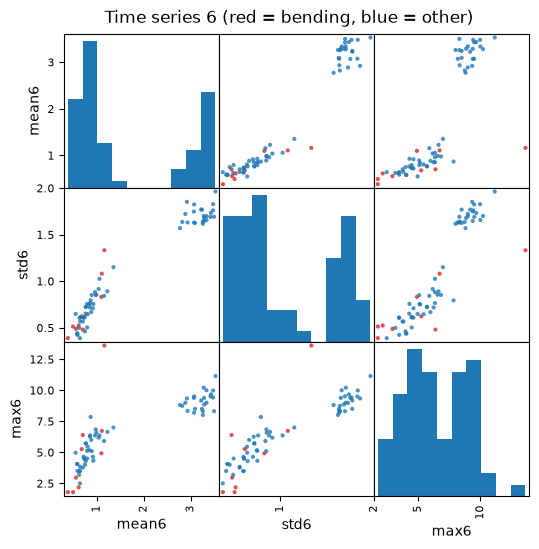

In [5]:
y_bin = y_train.str.startswith("bending").astype(int).values
colors = np.where(y_bin == 1, "tab:red", "tab:blue")
print("bending:", y_bin.sum(), " other:", (1 - y_bin).sum())

sel_stats  = ["mean", "std", "max"]
sel_series = [1, 2, 6]

for k in sel_series:
    X = features_train[[f"{s}{k}" for s in sel_stats]]
    axes = pd.plotting.scatter_matrix(X, c=colors, figsize=(6, 6), alpha=0.8, diagonal="hist")
    plt.suptitle(f"Time series {k} (red = bending, blue = other)", y=0.92)
    plt.show()

#### ii. Splitted Plots

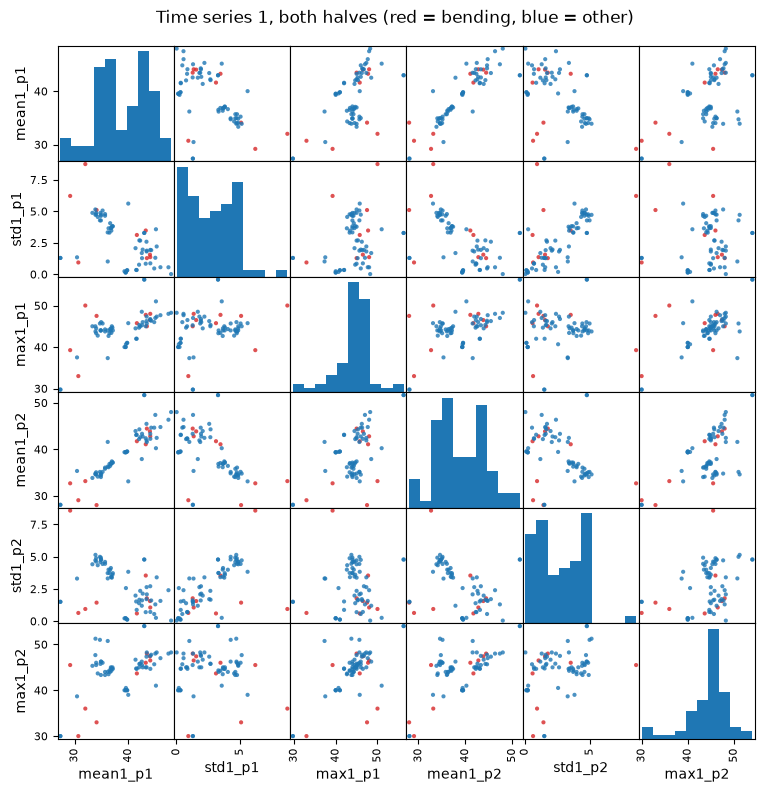

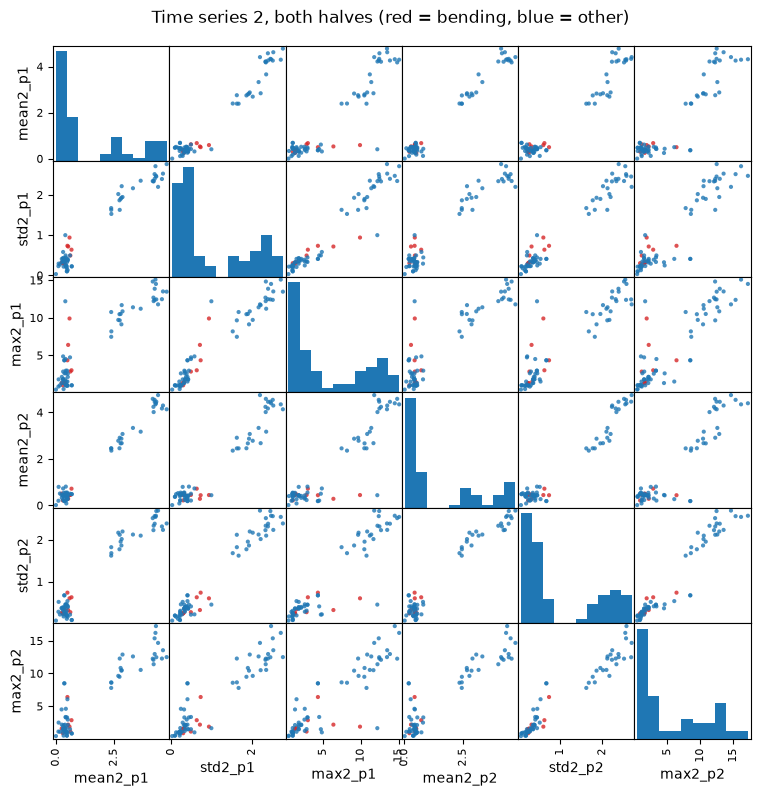

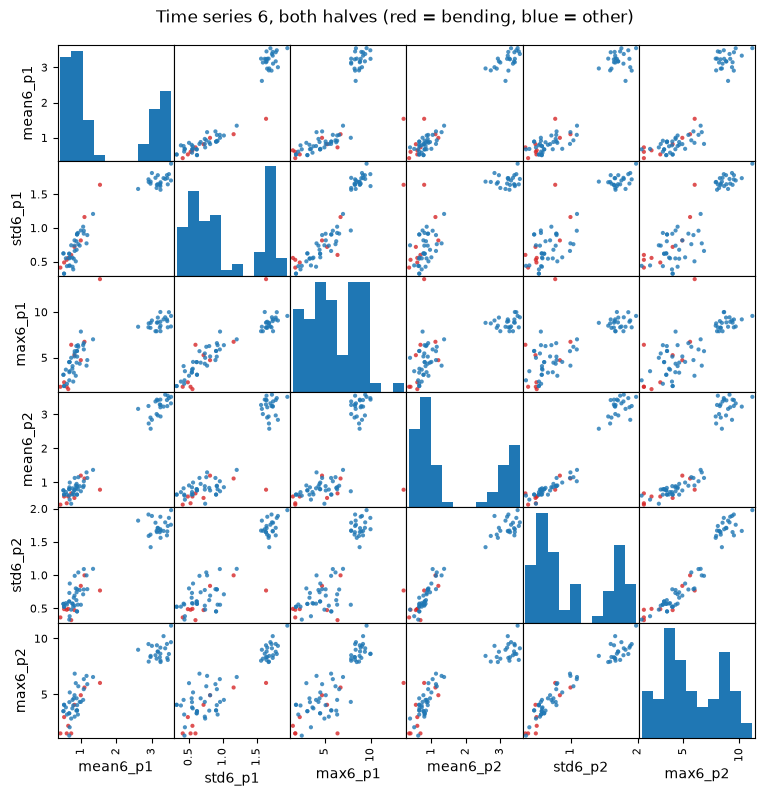

In [6]:
def extract_seg(inst, l, stats=("min", "max", "mean", "median", "std", "1st_quart", "3rd_quart")):
    fn = {
        "min": np.min, "max": np.max, "mean": np.mean, "median": np.median,
        "std": lambda x: x.std(ddof=1),
        "1st_quart": lambda x: np.percentile(x, 25),
        "3rd_quart": lambda x: np.percentile(x, 75),
    }
    feats = {}
    for k, c in enumerate(cols, start=1):
        for j, seg in enumerate(np.array_split(inst["data"][c].values, l), start=1):
            for s in stats:
                feats[f"{s}{k}_p{j}"] = fn[s](seg)
    return feats

feats_l2 = pd.DataFrame([extract_seg(i, 2, sel_stats) for i in train])

for k in sel_series:
    X = feats_l2[[f"{s}{k}_p{j}" for j in (1, 2) for s in sel_stats]]
    pd.plotting.scatter_matrix(X, c=colors, figsize=(9, 9), alpha=0.8, diagonal="hist")
    plt.suptitle(f"Time series {k}, both halves (red = bending, blue = other)", y=0.92)
    plt.show()

There's no considerable difference. The bending entries still overlap with other activities in series 1 and stay in low variability cluster in series 2 and 6. The features from the two halves are strongly correlated.

#### iii. Time Series Segments

 l  p   cv_acc
12  1 0.985714
 3  1 0.971429
14  1 0.971429
16  1 0.971429
17  1 0.971429
12  2 0.971429
17  5 0.971429
19  8 0.971429
10  1 0.957143
 8  1 0.957143
best (l, p) = (12, 1);  majority-class baseline acc = 0.870


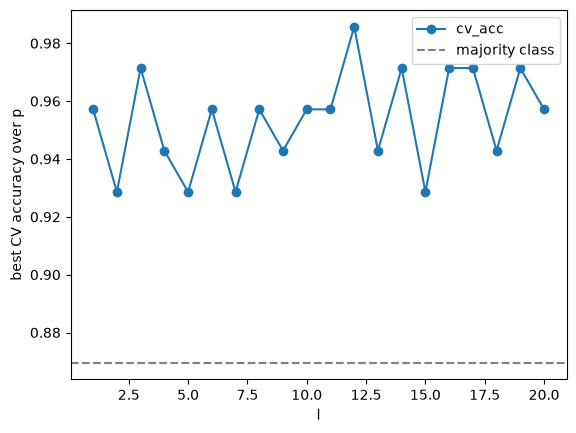

selected: ['mean5_p2']


In [7]:
RS = 552
P_LIST = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40, 50, 60, 80, 100]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
make_lr = lambda: LogisticRegression(C=1e6, max_iter=300)
warnings.filterwarnings("ignore")

feats_tr = {l: pd.DataFrame([extract_seg(i, l, sel_stats) for i in train]) for l in range(1, 21)}

rows = []
for l, Xdf in feats_tr.items():
    X = Xdf.values
    ps = [p for p in P_LIST if p <= X.shape[1]]
    accs = {p: [] for p in ps}
    for tr, va in skf.split(X, y_bin):
        sc = StandardScaler().fit(X[tr])
        Xt, Xv = sc.transform(X[tr]), sc.transform(X[va])
        for p in ps:
            rfe = RFE(make_lr(), n_features_to_select=p, step=1).fit(Xt, y_bin[tr])
            accs[p].append(rfe.score(Xv, y_bin[va]))
    rows += [{"l": l, "p": p, "cv_acc": np.mean(a)} for p, a in accs.items()]

cv_res = pd.DataFrame(rows)
ranked = cv_res.sort_values(["cv_acc", "p", "l"], ascending=[False, True, True])
best_l, best_p = int(ranked.iloc[0].l), int(ranked.iloc[0].p)
print(ranked.head(10).to_string(index=False))
print(f"best (l, p) = ({best_l}, {best_p});  majority-class baseline acc = {1 - y_bin.mean():.3f}")

cv_res.groupby("l").cv_acc.max().plot(marker="o")
plt.axhline(1 - y_bin.mean(), ls="--", c="gray", label="majority class")
plt.xlabel("l"); plt.ylabel("best CV accuracy over p"); plt.legend(); plt.show()

feat_names = list(feats_tr[best_l].columns)
scaler = StandardScaler().fit(feats_tr[best_l].values)
Xs = scaler.transform(feats_tr[best_l].values)
rfe_final = RFE(make_lr(), n_features_to_select=best_p, step=1).fit(Xs, y_bin)
keep = np.flatnonzero(rfe_final.support_)
Xtr_s = Xs[:, keep]
sel_names = [feat_names[j] for j in keep]
final_model = make_lr().fit(Xtr_s, y_bin)
print("selected:", sel_names)

In [8]:
wrong = cross_val_score(make_lr(), Xtr_s, y_bin, cv=skf).mean()
right = ranked.iloc[0].cv_acc
print(f"right-way CV acc = {right:.3f}   wrong-way CV acc = {wrong:.3f}")

right-way CV acc = 0.986   wrong-way CV acc = 0.986


In [9]:
l_demo, p_demo = 20, 10
Xw = StandardScaler().fit_transform(feats_tr[l_demo].values)
kw = np.flatnonzero(RFE(make_lr(), n_features_to_select=p_demo, step=1).fit(Xw, y_bin).support_)
wrong = cross_val_score(make_lr(), Xw[:, kw], y_bin, cv=skf).mean()
right = cv_res.query("l == @l_demo and p == @p_demo").cv_acc.iloc[0]
print(f"l={l_demo}, p={p_demo}:  right-way {right:.3f}   wrong-way {wrong:.3f}")

l=20, p=10:  right-way 0.943   wrong-way 1.000


Right way: do scaling and feature selection inside each training fold and evaluate only on the left out fold.

Wrong way: select features on all training data first and then cross-validate. It leaks the validation labels into the selection.

Stratified CV keeps the class proportion ($\approx 13\%$: 9 bending vs 60 other) in every fold. Best (l, p) = (12, 1), CV accuracy 0.986.

#### iv. Confusion Matrix

[[60  0]
 [ 1  8]]
train acc: 0.9855072463768116


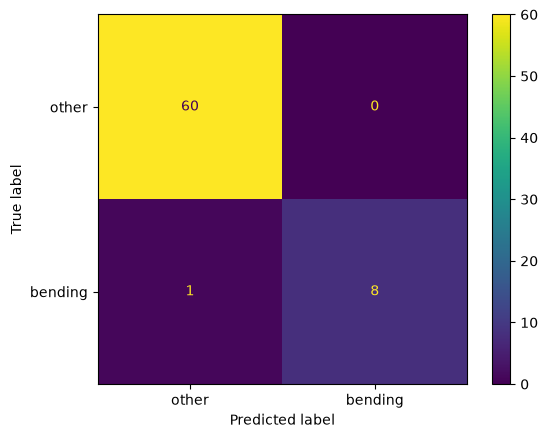

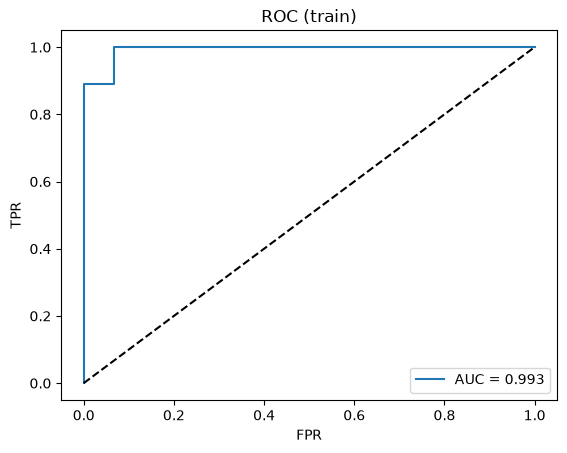

             beta  p_value
intercept -5.7710   0.0112
mean5_p2   8.2319   0.0380


In [10]:
pred = final_model.predict(Xtr_s)
prob = final_model.predict_proba(Xtr_s)[:, 1]
print(confusion_matrix(y_bin, pred))
print("train acc:", accuracy_score(y_bin, pred))
ConfusionMatrixDisplay.from_predictions(y_bin, pred, display_labels=["other", "bending"]); plt.show()

fpr, tpr, _ = roc_curve(y_bin, prob); auc_tr = roc_auc_score(y_bin, prob)
plt.plot(fpr, tpr, label=f"AUC = {auc_tr:.3f}"); plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("ROC (train)"); plt.legend(); plt.show()

try:
    res = sm.Logit(y_bin, sm.add_constant(Xtr_s)).fit(disp=0, maxiter=200)
    coef_tbl = pd.DataFrame({"beta": res.params, "p_value": res.pvalues}, index=["intercept"] + sel_names)
except Exception as e:
    print("statsmodels failed (likely perfect separation):", type(e).__name__)
    coef_tbl = pd.DataFrame({"beta": np.r_[final_model.intercept_, final_model.coef_[0]]},
                            index=["intercept"] + sel_names)
print(coef_tbl.round(4))

#### v. Test Classifier

In [11]:
y_test_bin = y_test.str.startswith("bending").astype(int).values
Xte = scaler.transform(
    pd.DataFrame([extract_seg(i, best_l, sel_stats) for i in test])[feat_names].values)[:, keep]

pred_te = final_model.predict(Xte); prob_te = final_model.predict_proba(Xte)[:, 1]
print(confusion_matrix(y_test_bin, pred_te))
print(f"test acc = {accuracy_score(y_test_bin, pred_te):.3f}   "
      f"CV acc = {ranked.iloc[0].cv_acc:.3f}   train acc = {accuracy_score(y_bin, pred):.3f}")
print("test AUC:", roc_auc_score(y_test_bin, prob_te))

[[14  1]
 [ 1  3]]
test acc = 0.895   CV acc = 0.986   train acc = 0.986
test AUC: 0.85


Test accuracy (0.895) is lower than the CV accuracy (0.986). The CV accuracy was the maximum over the (l, p) grid, so it is optimistic and the test set is small.

#### vi. Separation

In [12]:
for l in [1, 2, 5, 10, 20]:
    Xl = StandardScaler().fit_transform(feats_tr[l].values)
    m = make_lr().fit(Xl, y_bin)
    print(f"l={l:2d} all feats: train acc={m.score(Xl, y_bin):.3f}  max|beta|={np.abs(m.coef_).max():.1f}")
print(f"selected model: train acc={final_model.score(Xtr_s, y_bin):.3f}  "
      f"max|beta|={np.abs(final_model.coef_).max():.1f}")

l= 1 all feats: train acc=1.000  max|beta|=7.8
l= 2 all feats: train acc=1.000  max|beta|=4.6
l= 5 all feats: train acc=1.000  max|beta|=2.0
l=10 all feats: train acc=1.000  max|beta|=1.4
l=20 all feats: train acc=1.000  max|beta|=1.2
selected model: train acc=0.986  max|beta|=8.2


For the selected model we get one training error and a finite coefficient ($\beta = 8.2$), so no apparent instability. The classes are separable with all the features, which would cause instability.

#### vii. Imbalance

train acc: 0.9420289855072463  AUC: 0.993
[[56  4]
 [ 0  9]]
test acc: 0.7894736842105263  AUC: 0.85
[[12  3]
 [ 1  3]]


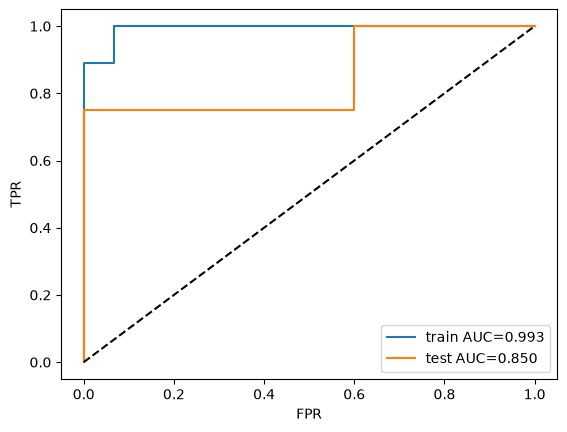

In [13]:
B, RATIO = 50, 1
rng = np.random.default_rng(RS)
cases, ctrls = np.where(y_bin == 1)[0], np.where(y_bin == 0)[0]
n_s = RATIO * len(cases)

ws, bs = [], []
for _ in range(B):
    idx = np.r_[cases, rng.choice(ctrls, n_s, replace=False)]
    m = make_lr().fit(Xtr_s[idx], y_bin[idx])
    ws.append(m.coef_[0]); bs.append(m.intercept_[0])
w, b = np.mean(ws, 0), np.mean(bs)

pi_pop = y_bin.mean(); pi_s = len(cases) / (len(cases) + n_s)
b_adj = b - np.log(pi_s / (1 - pi_s)) + np.log(pi_pop / (1 - pi_pop))
sig = lambda z: 1 / (1 + np.exp(-z))

for name, X_, y_ in [("train", Xtr_s, y_bin), ("test", Xte, y_test_bin)]:
    pr = sig(X_ @ w + b_adj)
    print(name, "acc:", accuracy_score(y_, pr > 0.5), " AUC:", round(roc_auc_score(y_, pr), 3))
    print(confusion_matrix(y_, (pr > 0.5).astype(int)))
    f, t, _ = roc_curve(y_, pr); plt.plot(f, t, label=f"{name} AUC={roc_auc_score(y_, pr):.3f}")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(); plt.show()

Yes, 9 bending vs 60 other. I used case control sampling and adjusted the intercept for the original class proportion.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

 l        C   cv_acc
12 1.000000 0.985714
 1 0.316228 0.971429
 3 0.316228 0.971429
16 1.000000 0.971429
19 1.000000 0.971429
20 1.000000 0.971429
 1 3.162278 0.971429
12 3.162278 0.971429
18 3.162278 0.971429
19 3.162278 0.971429
best (l, C) = (12, 1);  majority baseline = 0.870


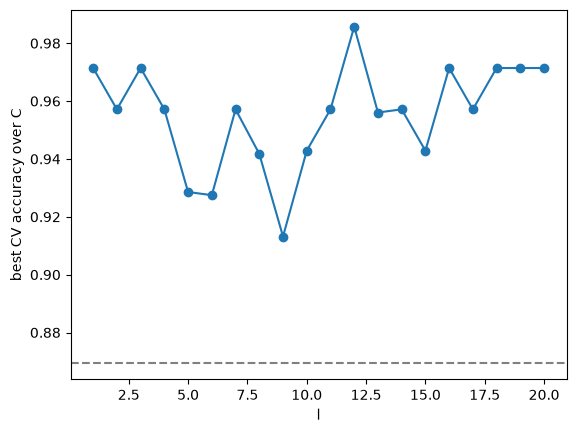

5 of 216 features kept: {'max1_p7': np.float64(-0.646), 'std3_p3': np.float64(0.082), 'mean5_p2': np.float64(2.332), 'mean5_p11': np.float64(0.293), 'max6_p11': np.float64(-0.67)}
train: acc=1.000  AUC=1.000
[[60  0]
 [ 0  9]]
test: acc=0.947  AUC=0.983
[[15  0]
 [ 1  3]]


In [14]:
C_GRID = np.logspace(-2, 2, 9)
mk_l1 = lambda C=1.0: make_pipeline(StandardScaler(),
                                    LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=1000))

rows = []
for l, Xdf in feats_tr.items():
    gs = GridSearchCV(mk_l1(), {"logisticregression__C": C_GRID}, cv=skf, scoring="accuracy").fit(Xdf.values, y_bin)
    rows += [{"l": l, "C": c, "cv_acc": s} for c, s in zip(C_GRID, gs.cv_results_["mean_test_score"])]

cv_l1 = pd.DataFrame(rows)
ranked_l1 = cv_l1.sort_values(["cv_acc", "C", "l"], ascending=[False, True, True])
best_l1, best_C = int(ranked_l1.iloc[0]["l"]), float(ranked_l1.iloc[0]["C"])
print(ranked_l1.head(10).to_string(index=False))
print(f"best (l, C) = ({best_l1}, {best_C:.3g});  majority baseline = {1 - y_bin.mean():.3f}")

cv_l1.groupby("l").cv_acc.max().plot(marker="o")
plt.axhline(1 - y_bin.mean(), ls="--", c="gray"); plt.xlabel("l"); plt.ylabel("best CV accuracy over C"); plt.show()

names_l1 = list(feats_tr[best_l1].columns)
Xtr_l1 = feats_tr[best_l1].values
Xte_l1 = pd.DataFrame([extract_seg(i, best_l1, sel_stats) for i in test])[names_l1].values
pipe_l1 = mk_l1(best_C).fit(Xtr_l1, y_bin)
coef = pipe_l1[-1].coef_[0]; nz = np.flatnonzero(coef)
print(f"{len(nz)} of {len(coef)} features kept:", {names_l1[j]: round(coef[j], 3) for j in nz})

for name, X_, y_ in [("train", Xtr_l1, y_bin), ("test", Xte_l1, y_test_bin)]:
    pred, prob = pipe_l1.predict(X_), pipe_l1.predict_proba(X_)[:, 1]
    print(f"{name}: acc={accuracy_score(y_, pred):.3f}  AUC={roc_auc_score(y_, prob):.3f}")
    print(confusion_matrix(y_, pred))

#### ii. Comparison

L1 performs slightly better. Same CV accuracy (0.986) but higher test accuracy (0.947 vs 0.895).

L1 is easier to implement. Feature selection happens inside the fit and only C needs tuning instead of refitting RFE for every p.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

 l          C   cv_acc
 1   1.000000 0.928571
 1   4.641589 0.914286
 2   1.000000 0.884615
 3  21.544347 0.871429
 5  21.544347 0.871429
 3 100.000000 0.871429
 5 100.000000 0.871429
 1   0.215443 0.870330
 2  21.544347 0.869231
 2 100.000000 0.869231
best (l, C) = (1, 1)


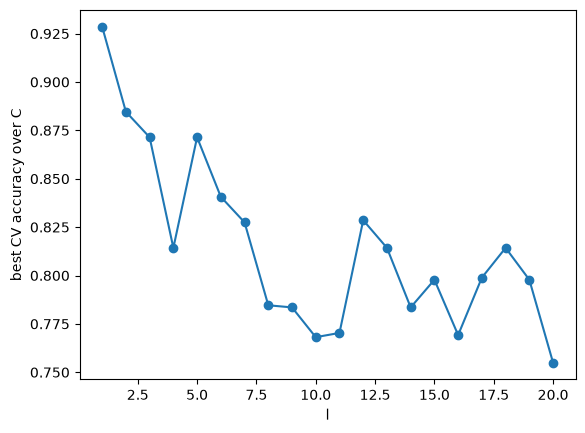

features used by at least one class: 14 of 18
test accuracy = 0.947   test error = 0.053
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         0         2        0      0        0         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        0      3        0         0        0
sitting          0         0        0      0        3         0        0
standing         0         0        0      0        1         2        0
walking          0         0        0      0        0         0        3


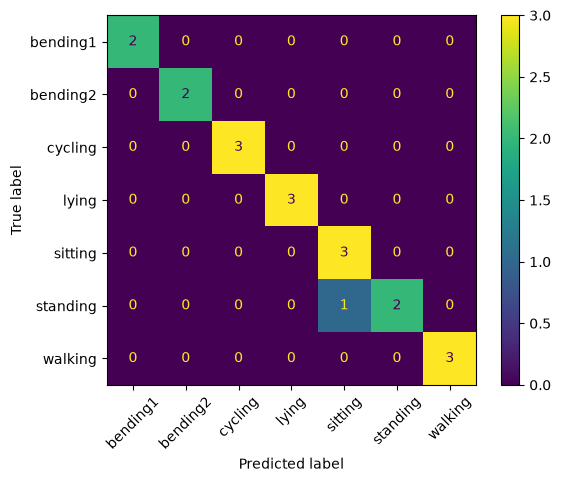

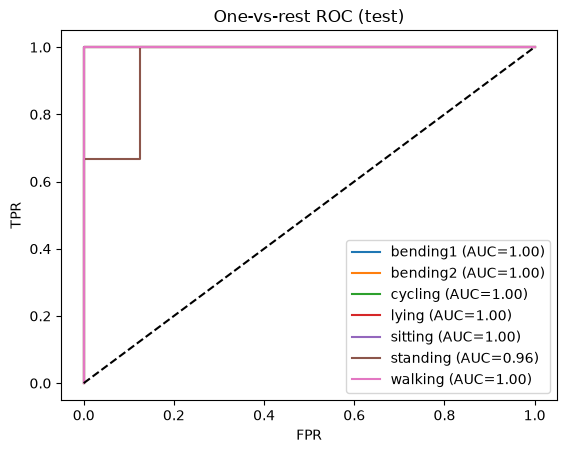

macro one-vs-rest AUC: 0.994047619047619


In [15]:
C_GRID_MC = np.logspace(-2, 2, 7)
mk_mc = lambda C=1.0: make_pipeline(StandardScaler(),
                                    LogisticRegression(penalty="l1", solver="saga", C=C, max_iter=5000, tol=1e-3))

rows = []
for l, Xdf in feats_tr.items():
    gs = GridSearchCV(mk_mc(), {"logisticregression__C": C_GRID_MC}, cv=skf, scoring="accuracy").fit(Xdf.values, y_train)
    rows += [{"l": l, "C": c, "cv_acc": s} for c, s in zip(C_GRID_MC, gs.cv_results_["mean_test_score"])]

cv_mc = pd.DataFrame(rows)
ranked_mc = cv_mc.sort_values(["cv_acc", "C", "l"], ascending=[False, True, True])
best_l_mc, best_C_mc = int(ranked_mc.iloc[0]["l"]), float(ranked_mc.iloc[0]["C"])
print(ranked_mc.head(10).to_string(index=False))
print(f"best (l, C) = ({best_l_mc}, {best_C_mc:.3g})")

cv_mc.groupby("l").cv_acc.max().plot(marker="o"); plt.xlabel("l"); plt.ylabel("best CV accuracy over C"); plt.show()

names_mc = list(feats_tr[best_l_mc].columns)
Xte_mc = pd.DataFrame([extract_seg(i, best_l_mc, sel_stats) for i in test])[names_mc].values
pipe_mc = mk_mc(best_C_mc).fit(feats_tr[best_l_mc].values, y_train)
classes = pipe_mc[-1].classes_
coefs = pipe_mc[-1].coef_
print(f"features used by at least one class: {(coefs != 0).any(axis=0).sum()} of {coefs.shape[1]}")

pred = pipe_mc.predict(Xte_mc); prob = pipe_mc.predict_proba(Xte_mc)
print(f"test accuracy = {accuracy_score(y_test, pred):.3f}   test error = {1 - accuracy_score(y_test, pred):.3f}")
print(pd.DataFrame(confusion_matrix(y_test, pred, labels=classes), index=classes, columns=classes))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=classes, xticks_rotation=45); plt.show()

Y_te = label_binarize(y_test, classes=classes)
for k, c in enumerate(classes):
    f, t, _ = roc_curve(Y_te[:, k], prob[:, k])
    plt.plot(f, t, label=f"{c} (AUC={roc_auc_score(Y_te[:, k], prob[:, k]):.2f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("One-vs-rest ROC (test)"); plt.legend(); plt.show()
print("macro one-vs-rest AUC:", roc_auc_score(y_test, prob, multi_class="ovr", average="macro"))

Test error = 0.053 (1 of 19 misclassified).

#### ii. Naive Bayes

== Gaussian NB: best l = 1, CV acc = 0.929
   test acc = 0.895   test error = 0.105   macro OvR AUC = 0.997
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         0         1        0      0        1         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        0      3        0         0        0
sitting          0         0        0      0        3         0        0
standing         0         0        0      0        1         2        0
walking          0         0        0      0        0         0        3


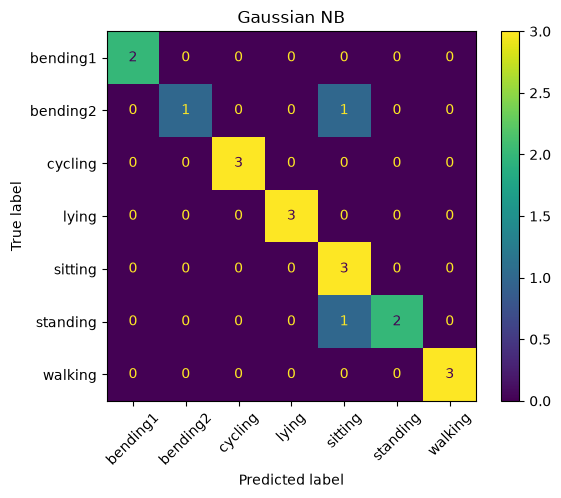

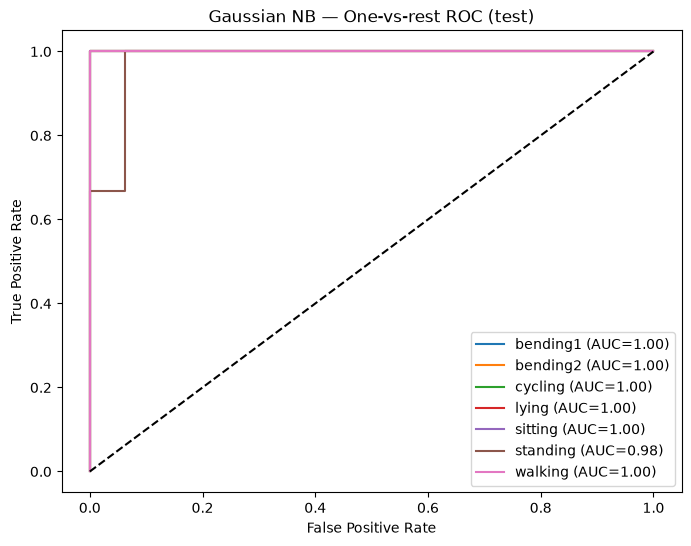

== Multinomial NB: best l = 5, CV acc = 0.812
   test acc = 0.789   test error = 0.211   macro OvR AUC = 0.966
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         0         1        0      0        0         1        0
cycling          0         0        3      0        0         0        0
lying            0         0        0      2        1         0        0
sitting          0         0        0      0        2         1        0
standing         0         0        0      0        1         2        0
walking          0         0        0      0        0         0        3


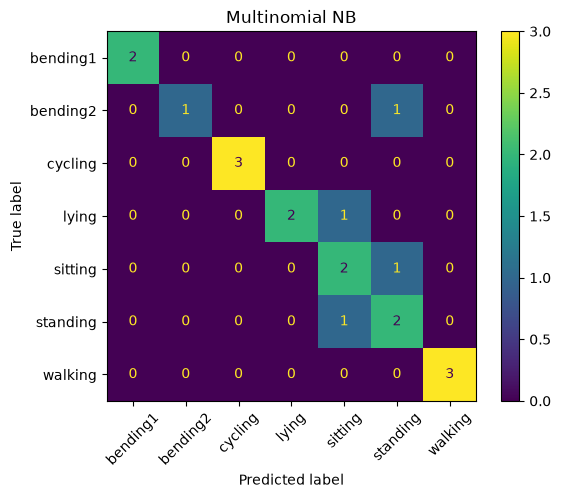

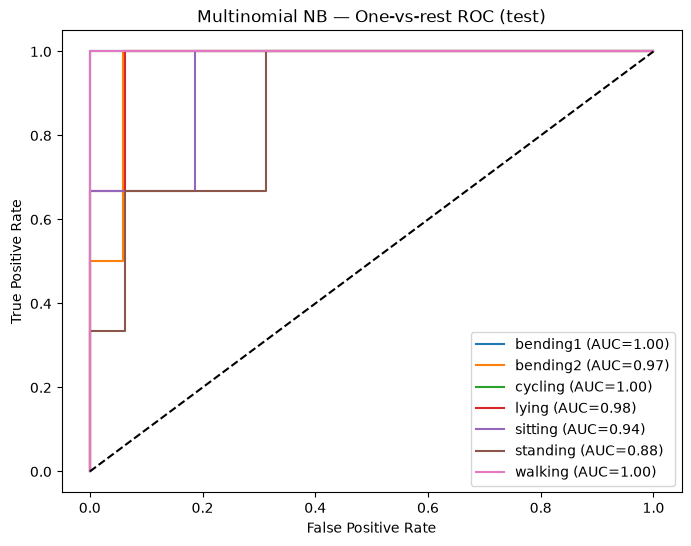

In [16]:
nb_models = {
    "Gaussian NB":    lambda: GaussianNB(),
    "Multinomial NB": lambda: make_pipeline(MinMaxScaler(clip=True), MultinomialNB()),
}

for name, mk in nb_models.items():
    cv_acc = {l: cross_val_score(mk(), Xdf.values, y_train, cv=skf, scoring="accuracy").mean()
              for l, Xdf in feats_tr.items()}
    l_nb = max(cv_acc, key=lambda l: (cv_acc[l], -l))
    names_nb = list(feats_tr[l_nb].columns)
    model = mk().fit(feats_tr[l_nb].values, y_train)
    Xte_nb = pd.DataFrame([extract_seg(i, l_nb, sel_stats) for i in test])[names_nb].values
    pred, prob = model.predict(Xte_nb), model.predict_proba(Xte_nb)
    cls = model.classes_
    print(f"== {name}: best l = {l_nb}, CV acc = {cv_acc[l_nb]:.3f}")
    print(f"   test acc = {accuracy_score(y_test, pred):.3f}   test error = {1 - accuracy_score(y_test, pred):.3f}   "
          f"macro OvR AUC = {roc_auc_score(y_test, prob, multi_class='ovr'):.3f}")
    print(pd.DataFrame(confusion_matrix(y_test, pred, labels=cls), index=cls, columns=cls))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=cls, xticks_rotation=45); plt.title(name); plt.show()
    Y_te_nb = label_binarize(y_test, classes=cls)

    plt.figure(figsize=(8, 6))
    for k, activity in enumerate(cls):
        fpr, tpr, _ = roc_curve(Y_te_nb[:, k], prob[:, k])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{activity} (AUC={roc_auc:.2f})")

    plt.plot([0, 1], [0, 1], "k--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{name} — One-vs-rest ROC (test)")
    plt.legend()
    plt.show()

Gaussian NB: test error 0.105

Multinomial NB: test error 0.211

Gaussian NB is better, because Multinomial NB assumes count-like features and these features are continuous.

#### iii. Comparison

L1 multinomial regression is best (test error 0.053), then Gaussian NB (0.105), then Multinomial NB (0.211) on this dataset. The differences between successive models are 1 to 2 test instances out of 19.

## 3. ISLR 4.8.3

The Bayes classifier assigns x to the class with the largest $\pi_k f_k(x)$, where $f_k(x)=\frac{1}{\sqrt{2\pi}\sigma_k}e^{-(x-\mu_k)^2/2\sigma_k^2}$. Taking logs and dropping terms that don't depend on $k$:
$$\delta_k(x)=-\frac{x^2}{2\sigma_k^2}+\frac{\mu_k}{\sigma_k^2}x-\frac{\mu_k^2}{2\sigma_k^2}+\log\pi_k-\log\sigma_k .$$
The $x^2$ coefficient depends on $k$, so when the variances differ it doesn't cancel between classes. The boundary $\delta_k(x)=\delta_l(x)$ is quadratic in $x$, so the Bayes classifier is quadratic, not linear. If all $\sigma_k$ were equal, the $x^2$ terms would cancel and it would be linear (LDA).

## 4. ISLR 4.8.7

With $\pi_1=0.8$, $\pi_0=0.2$, $\mu_1=10$, $\mu_0=0$, $\sigma^2=36$ and $x=4$ (the Gaussian constant cancels):
$$P(Y=1\mid X=4)=\frac{0.8\,e^{-(4-10)^2/72}}{0.8\,e^{-(4-10)^2/72}+0.2\,e^{-(4-0)^2/72}}=\frac{0.8e^{-0.5}}{0.8e^{-0.5}+0.2e^{-0.222}}\approx 0.752.$$

In [17]:
f = lambda x, m, s2: np.exp(-(x-m)**2/(2*s2)) / np.sqrt(2*np.pi*s2)
num = 0.8*f(4, 10, 36)
print(num / (num + 0.2*f(4, 0, 36)))

0.7518524532975261


## 5.1. Extra Practice ISLR 4.8.4

a) For $p = 1$: $0.1^1 = 0.1$. About 10% of the observations.

b) For $p = 2$: $0.1^2 = 0.01$. About 1% of the observations.

c) For $p = 100$: $0.1^{100} = 10^{-100}$. Essentially 0%.

d) As $p$ grows the value of $0.1^p$ shrinks exponentially. For larger $p$ the KNN neighbourhood has practically no training observations.

e) Setting $s^p = 0.1$, we get $s = 0.1^{1/p}$

- $p = 1$: $s = 0.1^{1/1} = 0.10$
- $p = 2$: $s = 0.1^{1/2} \approx 0.316$
- $p = 100$: $s = 0.1^{1/100} \approx 0.977$

For $p = 100$ the hypercube spans about 98% of the range to cover 10% of the data.

In [18]:
print(0.1, 0.1**2, 0.1**100)
print([0.1**(1/p) for p in (1, 2, 100)])

0.1 0.010000000000000002 1.0000000000000056e-100
[0.1, 0.31622776601683794, 0.9772372209558107]


## 5.2. Extra Practice ISLR 4.8.9

$odds = p/(1-p)$

a) $p = odds/(odds + 1)$ => $p = 0.37/(1 + 0.37) = 0.27$. 27% of people with $odds = 0.37$ will default.

b) $odds = 0.16/(1 - 0.16) \approx 0.19$.

In [19]:
print(0.37/1.37, 0.16/0.84)

0.27007299270072993 0.1904761904761905


### AI Use Log:

#### Prompt:

I've attached my Homework 4 assignment PDF and my notebook template for context. Can you help me work through Problem 2 and the ISLR questions? For each part, explain the steps and include the relevant Python code with suggested variable names, plus the written answers, so I can run and test everything myself on the AReM data.
(Uploaded Homework4.pdf and bagai_sanchit_HW4.ipynb for context)

#### Response:

## Response:

### 2(a)i Binary Classification — Scatter Plots

Use the three selected features from Homework 3 (`mean`, `std`, `max`) for time series 1, 2, and 6. Create scatter matrices to compare bending against the other activities.

```python
sel_stats = ["mean", "std", "max"]
series_ids = [1, 2, 6]

for k in series_ids:
    cols = [f"{s}{k}" for s in sel_stats]
    plot_df = features_train[cols].copy()
    plot_df["class"] = y_bin

    pd.plotting.scatter_matrix(
        plot_df[cols],
        figsize=(8, 8),
        diagonal="hist",
        c=plot_df["class"],
        alpha=0.7
    )
    plt.suptitle(f"Series {k}")
    plt.show()
```

Bending overlaps with other activities, particularly in series 1. In series 2 and 6, bending lies mainly in the low-variability cluster, so the classes are not completely separated.

### 2(a)ii Split Each Series into Two Halves

Split each of the six time series into two approximately equal parts, extract the selected features from each half, and repeat the scatter plots.

```python
def extract_seg(inst, l, stats):
    feats = {}

    for k, c in enumerate(cols, start=1):
        parts = np.array_split(inst["data"][c].to_numpy(), l)

        for j, x in enumerate(parts, start=1):
            if "mean" in stats:
                feats[f"mean{k}_p{j}"] = x.mean()
            if "std" in stats:
                feats[f"std{k}_p{j}"] = x.std(ddof=1)
            if "max" in stats:
                feats[f"max{k}_p{j}"] = x.max()

    return feats
```

Splitting the time series does not change the number of instances, only the number of features.

There is no considerable difference in the scatter plots. Bending still overlaps with other activities in series 1 and remains in the low-variability cluster in series 2 and 6. The features from the two halves are strongly correlated.

### 2(a)iii Logistic Regression and Recursive Feature Elimination

For each \(l=1,\ldots,20\), divide the six time series into \(l\) segments and extract the three selected statistics. Use logistic regression with recursive feature elimination (RFE) to select \(p\) features.

Use stratified 5-fold cross-validation to select the best pair \((l,p)\). Scaling and feature selection must occur inside each training fold.

```python
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=552
)

def make_lr():
    return LogisticRegression(
        C=1e6, max_iter=300
    )

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("rfe", RFE(make_lr(), n_features_to_select=1)),
    ("lr", make_lr())
])
```

Search over \(l\) and \(p\), rebuilding the feature matrix for each \(l\) and evaluating the pipeline with cross-validation.

The right way performs scaling and feature selection within each training fold and evaluates only on the held-out fold. The wrong way selects features using all training labels before cross-validation, causing information leakage.

Stratified cross-validation approximately preserves the bending proportion of 13% in each fold.

The selected model has \(l=12\), \(p=1\), and cross-validation accuracy 0.986. Its selected feature is `mean5_p2`.

### 2(a)iv Training Confusion Matrix, ROC, AUC and Parameters

Evaluate the selected classifier on the training data.

```python
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, accuracy_score
)

y_pred = final_model.predict(Xtr_s)
y_prob = final_model.predict_proba(Xtr_s)[:, 1]

cm = confusion_matrix(y_bin, y_pred)
fpr, tpr, _ = roc_curve(y_bin, y_prob)
roc_auc = auc(fpr, tpr)

ConfusionMatrixDisplay(cm).plot()
plt.show()

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()
```

Use `statsmodels.Logit` to obtain coefficient estimates and p-values for the selected features.

```python
import statsmodels.api as sm

X_sm = sm.add_constant(Xtr_s)
result = sm.Logit(y_bin, X_sm).fit(disp=False)

print(result.params)
print(result.pvalues)
```

The training confusion matrix is `[[60, 0], [1, 8]]`, giving accuracy 0.986 and AUC 0.993. The selected standardized feature has coefficient approximately 8.23 and p-value 0.038.

### 2(a)v Test the Classifier

Apply the same segmentation and training-fitted scaler to the test set. Do not refit the feature selection or scaler on test data.

```python
y_test_pred = final_model.predict(Xte_s)
y_test_prob = final_model.predict_proba(Xte_s)[:, 1]

print(confusion_matrix(y_test_bin, y_test_pred))
print(accuracy_score(y_test_bin, y_test_pred))
```

The test confusion matrix is `[[14, 1], [1, 3]]`, with accuracy 0.895 and AUC 0.85.

Test accuracy is lower than the cross-validation accuracy of 0.986. Selecting the maximum CV score over the \((l,p)\) grid introduces optimism, and the test set contains only 19 instances.

### 2(a)vi Separation and Instability

Logistic regression can exhibit coefficient instability when classes are completely or nearly linearly separable, because unregularized maximum-likelihood coefficients can become arbitrarily large.

For the selected one-feature model, there is one training error and a finite coefficient of approximately 8.2, so there is no apparent instability.

With all extracted features, the classes are linearly separable in the tested configurations, which can cause instability in unregularized logistic regression.

### 2(a)vii Class Imbalance and Case-Control Sampling

The training data contains 9 bending instances and 60 other instances, so the classes are imbalanced.

Use all 9 bending cases and randomly sample 9 controls. Fit logistic regression repeatedly and adjust the intercept to account for the original class proportions.


For a model fitted to a case-control sample:

$$
\beta_{0,\text{adjusted}}
=
\beta_{0,\text{sample}}
+
\log\frac{\pi}{1-\pi}
-
\log\frac{\pi_s}{1-\pi_s}
$$

where $\pi$ is the original bending proportion and $\pi_s$ is the sampled bending proportion.

```python
from scipy.special import logit

pi = y_bin.mean()
pi_sample = 0.5

adjustment = logit(pi) - logit(pi_sample)
adjusted_intercept = model.intercept_[0] + adjustment
```

The case-control model gives training confusion matrix `[[56, 4], [0, 9]]` with AUC 0.993, and test confusion matrix `[[12, 3], [1, 3]]` with AUC 0.85.

### 2(b)i L1-Penalized Logistic Regression

Instead of RFE, use L1 regularization to perform feature selection automatically by shrinking some coefficients to zero.

Tune both the segmentation parameter \(l\) and regularization strength \(C\) using stratified cross-validation.

```python
from sklearn.model_selection import GridSearchCV

pipe_l1 = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(
        penalty="l1",
        solver="liblinear",
        max_iter=3000
    ))
])

grid = GridSearchCV(
    pipe_l1,
    {"lr__C": [0.01, 0.1, 1, 10, 100]},
    cv=cv,
    scoring="accuracy"
)
```

Repeat the grid search for each \(l\), then select the combination with the highest cross-validation accuracy.

The selected model has \(l=12\), \(C=1\), and CV accuracy 0.986.

### 2(b)ii Compare L1 with RFE

L1 performs slightly better on the test set. Both approaches have CV accuracy 0.986, but L1 achieves test accuracy 0.947 compared with 0.895 for RFE.

L1 is easier to implement because feature selection happens inside the model fit. For each segmentation choice, only the regularization parameter \(C\) needs tuning rather than separately refitting RFE for different numbers of selected features.

### 2(c)i Multiclass L1 Logistic Regression

For multiclass classification, predict all seven activity types rather than combining them into bending and other.

Use L1-penalized multinomial logistic regression and tune \(l\) and \(C\) using stratified cross-validation.

```python
multi_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(
        penalty="l1",
        solver="saga",
        max_iter=5000,
    ))
])
```

Evaluate the selected model using a multiclass confusion matrix and one-vs-rest ROC curves.

For multiclass ROC, each activity is treated as the positive class and the remaining activities as negative. The ROC curves are computed using the predicted probabilities for each activity.

The selected model uses \(l=1\), with test error 0.053 (1 of 19 instances misclassified).

### 2(c)ii Gaussian and Multinomial Naive Bayes

Use both Gaussian and Multinomial Naive Bayes with the same segmentation search.

Gaussian NB models continuous features using class-conditional Gaussian distributions.

Multinomial NB assumes nonnegative, count-like features. Since the extracted time-domain statistics can include continuous values, use a nonnegative transformation such as `MinMaxScaler`.

```python
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import MinMaxScaler

gaussian_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("nb", GaussianNB())
])

multinomial_pipe = Pipeline([
    ("scaler", MinMaxScaler(clip=True)),
    ("nb", MultinomialNB())
])
```

Gaussian NB achieves test error 0.105, while Multinomial NB has test error 0.211.

Gaussian NB performs better on this dataset. Multinomial NB's count-like feature assumption is less suitable for continuous time-domain statistics.

### 2(c)iii Compare Multiclass Methods

L1 multinomial logistic regression performs best, with test error 0.053, followed by Gaussian NB at 0.105 and Multinomial NB at 0.211.

The differences between successive models are only 1 to 2 test instances out of 19, so the observed ranking is specific to this small test set.


### 3. ISLR 4.8.3

The Bayes classifier assigns $x$ to the class maximizing $\pi_k f_k(x)$. For Gaussian class-conditional distributions,

$$
f_k(x)=\frac{1}{\sqrt{2\pi}\sigma_k}
\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).
$$

Taking logarithms and removing terms independent of the class gives

$$
\delta_k(x)
=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
+\log\pi_k-\log\sigma_k.
$$

When the variances differ between classes, the coefficient of $x^2$ depends on $k$ and does not cancel. Therefore, the decision boundary is generally quadratic rather than linear.

If the class variances are equal, the quadratic terms cancel, producing a linear discriminant function as in LDA.

### 4. ISLR 4.8.7

Given $\pi_1=0.8$, $\pi_0=0.2$, $\mu_1=10$, $\mu_0=0$, $\sigma^2=36$, and $x=4$, apply Bayes' theorem:

$$
P(Y=1\mid X=4)
=
\frac{0.8e^{-(4-10)^2/72}}
{0.8e^{-(4-10)^2/72}+0.2e^{-(4-0)^2/72}}
$$

$$
=
\frac{0.8e^{-0.5}}
{0.8e^{-0.5}+0.2e^{-0.2222}}
\approx 0.752.
$$

The common Gaussian normalization constant cancels because both classes have the same variance.

### References:

- scikit-learn RFE: https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.RFE.html
- scikit-learn StratifiedKFold: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html
- scikit-learn Pipeline: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
- scikit-learn LogisticRegression: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
- scikit-learn GridSearchCV: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
- scikit-learn ROC and AUC: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html
- statsmodels Logit: https://www.statsmodels.org/stable/generated/statsmodels.discrete.discrete_model.Logit.html
- scikit-learn GaussianNB: https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html
- scikit-learn MultinomialNB: https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html
- scikit-learn MinMaxScaler: https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html